In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import datetime as dt
import numpy as np
from scipy import stats
import zipfile

# Load Dataset

In [2]:
!kaggle datasets download -d olistbr/brazilian-ecommerce
with zipfile.ZipFile('brazilian-ecommerce.zip', 'r') as zip_ref:
    zip_ref.extractall('olist_data')

df1 = pd.read_csv('olist_data/olist_orders_dataset.csv')
df2 = pd.read_csv('olist_data/olist_customers_dataset.csv')

Dataset URL: https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce
License(s): CC-BY-NC-SA-4.0
brazilian-ecommerce.zip: Skipping, found more recently modified local copy (use --force to force download)


# Merge

In [3]:
kolom_sama = set(df1.columns).intersection(set(df2.columns))
kolom_duplikat = list(kolom_sama - {"customer_id"})
df_sales_bersih = df2.drop(columns=kolom_duplikat)

# Lakukan Join (Left Join dari data sales ke master)
df_merged = pd.merge(df_sales_bersih, df1, on="customer_id", how="left")
df_merged.head()

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,order_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP,00e7ee1b050b8499577073aeb2a297a1,delivered,2017-05-16 15:05:35,2017-05-16 15:22:12,2017-05-23 10:47:57,2017-05-25 10:35:35,2017-06-05 00:00:00
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP,29150127e6685892b6eab3eec79f59c7,delivered,2018-01-12 20:48:24,2018-01-12 20:58:32,2018-01-15 17:14:59,2018-01-29 12:41:19,2018-02-06 00:00:00
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP,b2059ed67ce144a36e2aa97d2c9e9ad2,delivered,2018-05-19 16:07:45,2018-05-20 16:19:10,2018-06-11 14:31:00,2018-06-14 17:58:51,2018-06-13 00:00:00
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP,951670f92359f4fe4a63112aa7306eba,delivered,2018-03-13 16:06:38,2018-03-13 17:29:19,2018-03-27 23:22:42,2018-03-28 16:04:25,2018-04-10 00:00:00
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP,6b7d50bd145f6fc7f33cebabd7e49d0f,delivered,2018-07-29 09:51:30,2018-07-29 10:10:09,2018-07-30 15:16:00,2018-08-09 20:55:48,2018-08-15 00:00:00


In [4]:
df_merged['order_status'].unique()

<ArrowStringArray>
[  'delivered',    'canceled',    'invoiced',     'shipped',  'processing',
 'unavailable',    'approved',     'created']
Length: 8, dtype: str

In [5]:
df_merged['customer_state'].unique()

<ArrowStringArray>
['SP', 'SC', 'MG', 'PR', 'RJ', 'RS', 'PA', 'GO', 'ES', 'BA', 'MA', 'MS', 'CE',
 'DF', 'RN', 'PE', 'MT', 'AM', 'AP', 'AL', 'RO', 'PB', 'TO', 'PI', 'AC', 'SE',
 'RR']
Length: 27, dtype: str

# Cleaning

In [6]:
df_merged.info()

<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 12 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   customer_id                    99441 non-null  str  
 1   customer_unique_id             99441 non-null  str  
 2   customer_zip_code_prefix       99441 non-null  int64
 3   customer_city                  99441 non-null  str  
 4   customer_state                 99441 non-null  str  
 5   order_id                       99441 non-null  str  
 6   order_status                   99441 non-null  str  
 7   order_purchase_timestamp       99441 non-null  str  
 8   order_approved_at              99281 non-null  str  
 9   order_delivered_carrier_date   97658 non-null  str  
 10  order_delivered_customer_date  96476 non-null  str  
 11  order_estimated_delivery_date  99441 non-null  str  
dtypes: int64(1), str(11)
memory usage: 29.2 MB


In [7]:
#formatting
df_merged['order_status'] = df_merged['order_status'].astype('category')
cols_to_convert = [
    'order_purchase_timestamp',
    'order_approved_at',
    'order_delivered_carrier_date',
    'order_delivered_customer_date',
    'order_estimated_delivery_date'
]
df_merged[cols_to_convert] = df_merged[cols_to_convert].apply(pd.to_datetime)

In [8]:
df_merged.info()

<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 12 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   customer_id                    99441 non-null  str           
 1   customer_unique_id             99441 non-null  str           
 2   customer_zip_code_prefix       99441 non-null  int64         
 3   customer_city                  99441 non-null  str           
 4   customer_state                 99441 non-null  str           
 5   order_id                       99441 non-null  str           
 6   order_status                   99441 non-null  category      
 7   order_purchase_timestamp       99441 non-null  datetime64[us]
 8   order_approved_at              99281 non-null  datetime64[us]
 9   order_delivered_carrier_date   97658 non-null  datetime64[us]
 10  order_delivered_customer_date  96476 non-null  datetime64[us]
 11  order_estimated_delivery_d

In [9]:
#misingness pattern
df_merged['is_canceled'] = df_merged['order_status'].apply(lambda x: 1 if x in ['canceled', 'unavailable'] else 0)
df_merged['is_delayed'] = 0

delivered_mask = (df_merged['order_status'] == 'delivered') & (df_merged['order_delivered_customer_date'].notna())
df_merged.loc[delivered_mask, 'is_delayed'] = np.where(
    df_merged.loc[delivered_mask, 'order_delivered_customer_date'] > df_merged.loc[delivered_mask, 'order_estimated_delivery_date'], 
    1, 
    0
)
df_merged['order_status'] = df_merged['order_status'].fillna('unknown')

In [10]:
df_merged.duplicated().sum()

np.int64(0)

# Analysis

## Trend Order Daily

In [11]:
df_merged['order_day'] = df_merged['order_purchase_timestamp'].dt.day_name()
days_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
daily_orders = df_merged.groupby('order_day')['order_id'].count().reindex(days_order).reset_index()

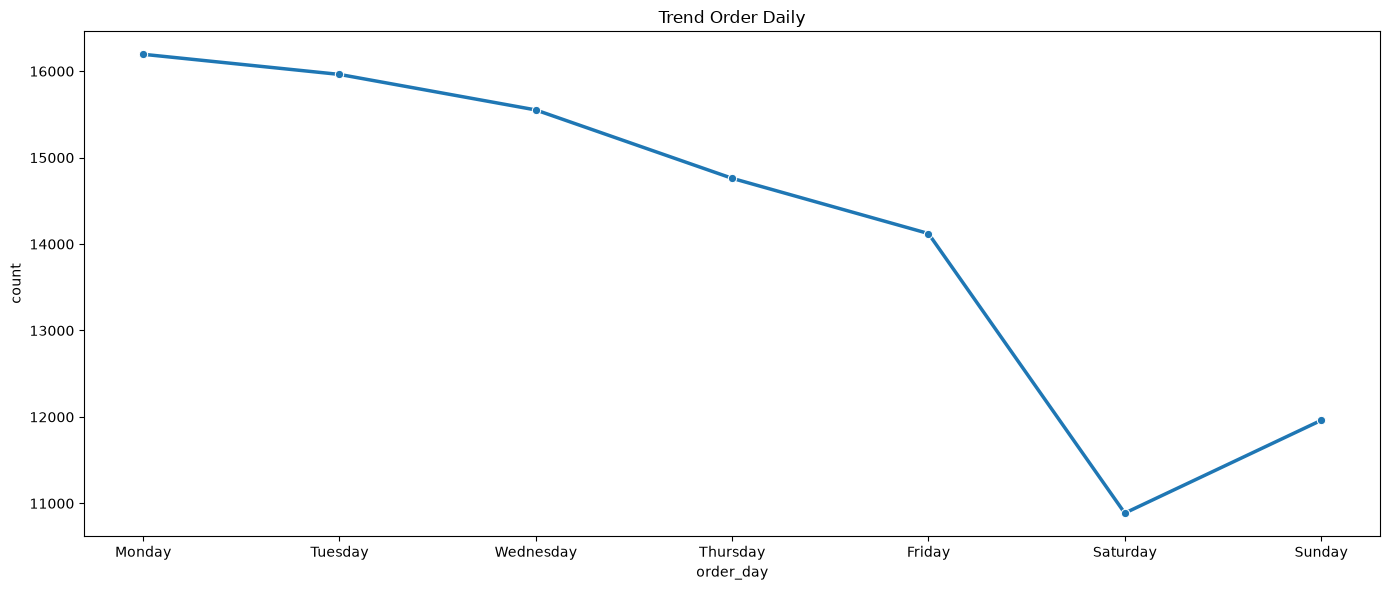

In [12]:
plt.figure(figsize=(14, 6))
sns.lineplot(data=daily_orders, x='order_day', y='order_id', marker='o', color='#1f77b4', linewidth=2.5)
plt.title("Trend Order Daily")
plt.ylabel("count")
plt.tight_layout()
plt.show()

Analyzing daily order trends shows that Olist marketplace activity peaks early in the week—with Mondays and Tuesdays driving the highest volume—before gradually tapering off to a weekend low on Saturday. This clear behavioral pattern provides valuable insights for timing promotional campaigns and managing inventory logistics effectively.

## Trend Order Monthly

In [13]:
df_merged['order_month'] = df_merged['order_purchase_timestamp'].dt.to_period('M')
monthly_orders = df_merged.groupby('order_month')['order_id'].count().reset_index()
monthly_orders['order_month'] = monthly_orders['order_month'].astype(str)

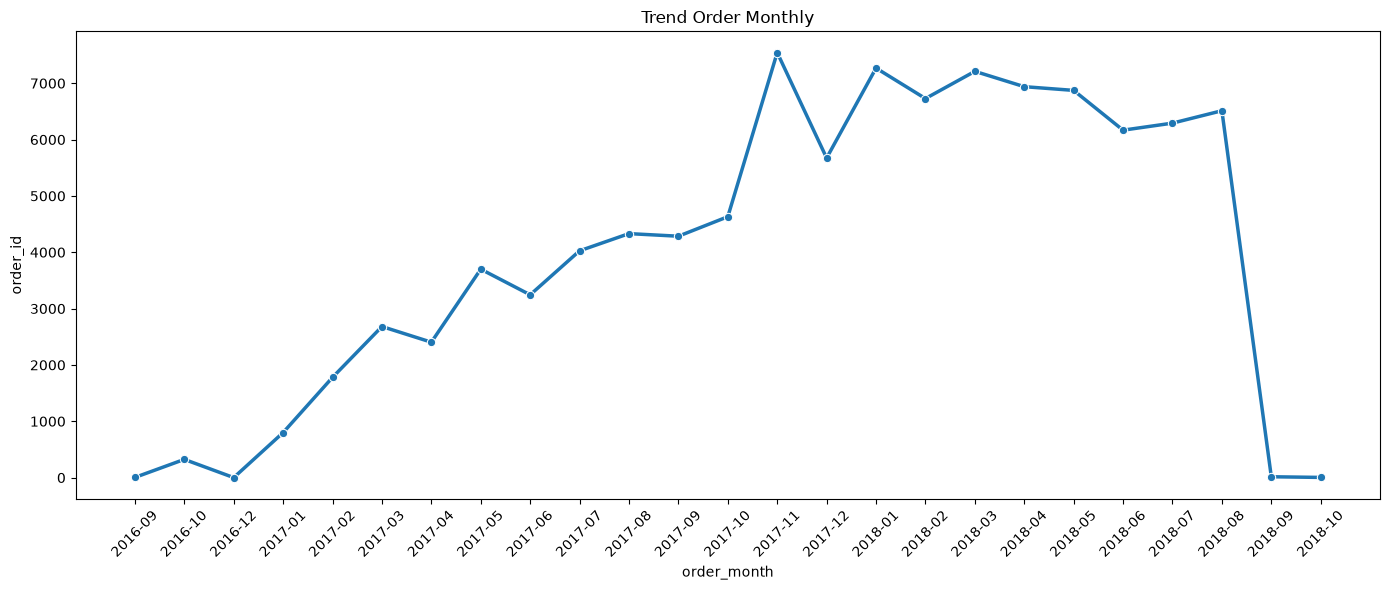

In [14]:
plt.figure(figsize=(14, 6))
sns.lineplot(data=monthly_orders, x='order_month', y='order_id', marker='o', color='#1f77b4', linewidth=2.5)
plt.title("Trend Order Monthly")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

The monthly order trend visualization reveals a powerful growth trajectory for the Olist marketplace from late 2016 through 2018. Starting from an early-stage baseline, the platform steadily scaled its order volume throughout 2017 before hitting a massive peak in November 2017 driven by seasonal shopping events. Entering 2018, transaction volume successfully stabilized into a high-throughput plateau, proving robust market adoption and operational maturity.

## Cohort Analysis

In [15]:
# find the first time buying and calculate the different month
df_merged['cohort_month'] = df_merged.groupby('customer_unique_id')['order_purchase_timestamp'].transform('min').dt.to_period('M')
year_diff = df_merged['order_month'].dt.year - df_merged['cohort_month'].dt.year
month_diff = df_merged['order_month'].dt.month - df_merged['cohort_month'].dt.month
df_merged['cohort_index'] = year_diff * 12 + month_diff + 1

In [16]:
#build the pivot table
cohort_data = df_merged.groupby(['cohort_month', 'cohort_index'])['customer_unique_id'].nunique().reset_index()
cohort_pivot = cohort_data.pivot(index='cohort_month', columns='cohort_index', values='customer_unique_id')

#calculate the retention
cohort_sizes = cohort_pivot.iloc[:, 0]
retention_matrix = cohort_pivot.divide(cohort_sizes, axis=0)

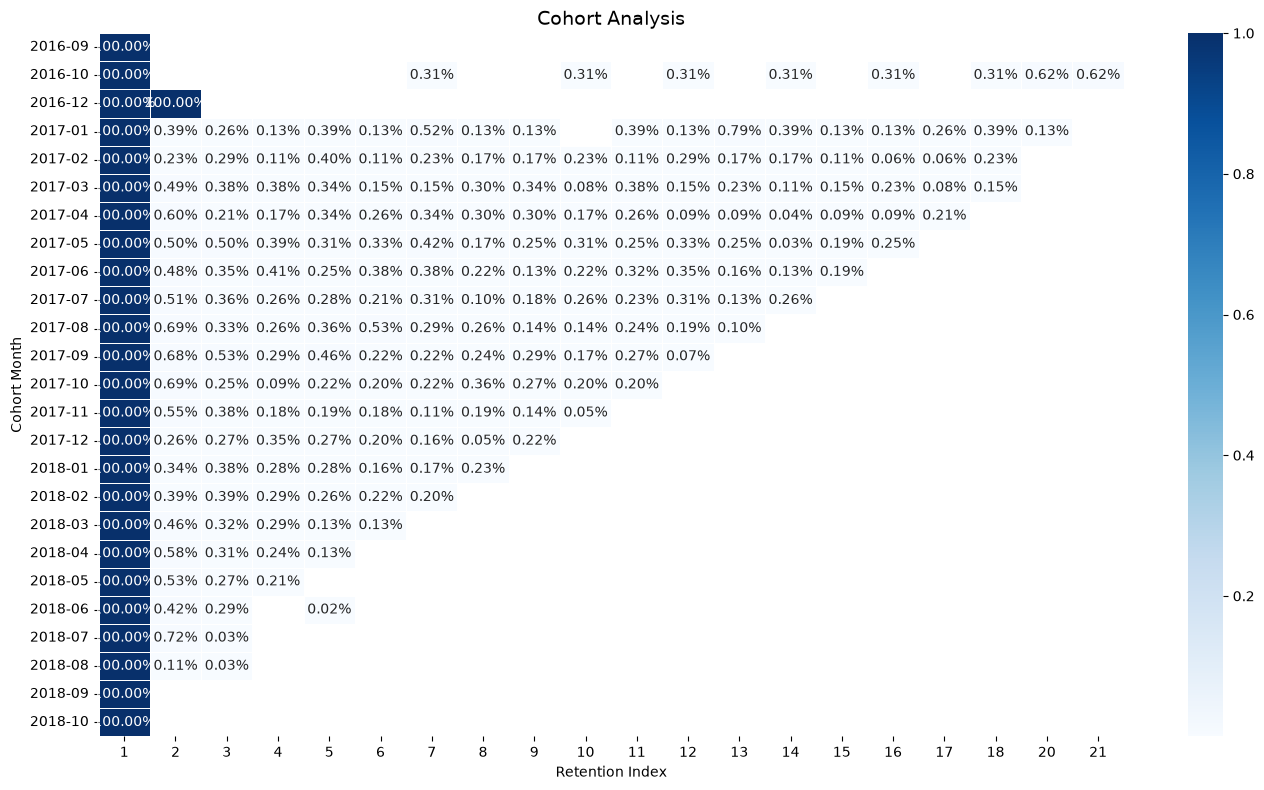

In [17]:
#Heatmap
plt.figure(figsize=(14, 8))
sns.heatmap(retention_matrix, annot=True, fmt='.2%', cmap='Blues', linewidths=0.5)
plt.title('Cohort Analysis', fontsize=14,)
plt.xlabel('Retention Index')
plt.ylabel('Cohort Month')
plt.tight_layout()
plt.show()

The cohort analysis heatmap highlights an extremely low customer retention rate across all cohorts, with month-over-month retention consistently dropping below 1% after the initial purchase. This pattern reveals that Olist operates primarily on a one-time transaction model, signaling a critical opportunity to shift focus from customer acquisition to repeat-purchase retention strategies.